# 05 · Métrica de negocio, benchmarks, costos y ROI — DataByte / RescateAlimento
**Capstone Samsung Innovation Campus · Producto 2 y pitch del 24/11 (ROI, costos, decisiones que habilita)**

## Qué responde este notebook (en el orden del pitch de 2 minutos)
1. **Problema situado** (Diana, Córdoba, noviembre 2026) y **métrica de negocio** redactada con los 3 elementos: *indicador · dirección · acción del modelo*.
2. **Qué medimos de verdad** (corrida de Apify, dataset real) y qué es un *supuesto*. Los supuestos están marcados con `# SUPUESTO`.
3. **Benchmarks** contra el mercado (otros actores de Apify, tarifas de Upwork, planes de n8n / AppSheet / FlutterFlow) **con URL**.
4. **Costos**: desarrollo (una vez) y operación (por mes), y **qué herramientas se contabilizan** (Apify, n8n, app de FlutterFlow, AppSheet).
5. **ROI** calculado con **la ficha de Diana** + los costos medidos, con sensibilidad, plazo de recuperación y un punto de equilibrio.

> **Regla del equipo:** el ROI no se arma con suposiciones. Usamos (a) los datos de la ficha de Diana, (b) lo que medimos en Apify y (c) precios publicados con su fuente.
> El único parámetro que *no* está medido es cuántas de las 12 horas semanales se automatizan realmente; por eso se muestra con sensibilidad y se propone **medirlo en un piloto**.
>
> ⚠️ **No usar en el pitch el «ROI 80 %» del notebook 03:** viene de datos SIMULADOS del bot y sirve para validar el procedimiento, no como resultado real.

## 0. Configuración y parámetros

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
OUT = Path("../data/processed") if Path("../data").exists() else Path("data/processed")
OUT.mkdir(parents=True, exist_ok=True)
SEMANAS_MES = 52 / 12            # una semana tiene 7 días; un mes ~4,33 semanas

# ---- 1) FICHA DE DIANA (hoja «Resumen» del Excel del Capstone) -------------------------------------------
FICHA = dict(
    horas_semana_manual = 12,       # horas semanales relevando precios y competencia a mano
    costo_hora_usd      = 8,        # costo de una hora de trabajo
    personas_equipo     = 3,        # equipo comercial
    error_publicaciones = 0.10,     # 1 de cada 10 publicaciones se carga con error
    ventas_meta_mes_usd = 15000,    # ventas mensuales del nuevo rubro (meta del primer año)
    presupuesto_setup   = 2500,     # presupuesto máximo de la solución
    presupuesto_mes     = 150,      # operación mensual máxima
    nps_actual          = 22,
)

# ---- 2) LO QUE MEDIMOS (captura de la corrida de Apify del 15/11/2026 y CSV del 16/11) -------------------
MEDIDO = dict(
    registros   = 22438,            # filas del dataset extraído (output de la corrida)
    segundos    = 3600,             # duración: la corrida terminó por TIMEOUT a los 3.600 s
    costo_corrida_usd = 0.315,      # costo que muestra Apify para esa corrida
    productos_unicos  = 3009,       # EAN distintos (notebook 00)
)

# ---- 3) PRECIOS PUBLICADOS (ver tabla de fuentes al final; consultados el 23/11/2026) ---------------------
TARIFA_HORA = {"DS": 35, "SE": 25, "BIZ": 20}   # extremo inferior de los rangos de Upwork (equipo junior)
HORAS = {"Etapa 1": {"DS": 12, "SE": 14, "BIZ": 8},     # SUPUESTO: horas de adaptación/entrega a Diana (reemplazar por bitácora real)
         "Etapa 2": {"DS": 14, "SE": 10, "BIZ": 6}}
N8N_STARTER_MES   = 24          # n8n Cloud Starter, facturación mensual (2.500 ejecuciones)
APIFY_STARTER_MES = 39          # Apify Starter (consumo prepago incluido); el plan Free da USD 5 de crédito
APPSHEET_USUARIO  = 5           # AppSheet Starter por usuario/mes
FLUTTERFLOW_BASIC = 39          # FlutterFlow Basic por mes (primer plan con exportación de código y publicación)
MARCA_CONSULTORA  = 0.30        # margen de la consultora (supuesto de ejemplo de la planilla)

# ---- 4) SUPUESTOS EXPLÍCITOS -------------------------------------------------------------------------------
HORAS_RESIDUALES_SEMANA = 2     # SUPUESTO: horas semanales que seguirían siendo manuales (revisión). Se valida en un piloto.
MANTENIMIENTO_H_MES     = 2     # SUPUESTO: horas/mes de mantenimiento (por si el sitio cambia) a tarifa BIZ
SEG_POR_PRECIO_MANUAL   = 30    # SUPUESTO: segundos que tarda una persona en buscar y anotar un precio (medir con cronómetro)
CORRIDAS_MES_DIARIO, CORRIDAS_MES_SEMANAL = 30, 4
HORAS_APP_FLUTTERFLOW   = 10    # SUPUESTO: horas de desarrollo de la app móvil (opcional) a tarifa SE
print("Parámetros cargados.")

Parámetros cargados.

## 1. Métrica de negocio (3 elementos) y métrica de modelo
**Definición de clase:** una métrica de negocio dice *para qué le sirve el modelo a la organización* (plata ganada, costos ahorrados, tiempo optimizado). Una métrica técnica dice qué tan bien predice el algoritmo.

| Elemento | Nuestra métrica de negocio |
|---|---|
| **Indicador concreto** | Horas semanales que el equipo de Diana dedica a relevar precios y competencia a mano (y su costo en USD) |
| **Dirección del cambio** | **Reducir** de 12 a 2 horas por semana (−83 %), es decir de USD 416 a USD 69 por mes |
| **Acción asociada al modelo** | La extracción diaria (Apify + n8n) reemplaza el relevamiento manual y el **Score de Rescate** le dice qué producto/lote reprecificar o promocionar *hoy* |

**Métrica de negocio redactada:** *«Reducir en un 83 % las horas semanales de relevamiento manual de precios (de 12 a 2) mediante la extracción automática diaria y el Score de Rescate, que indica qué producto o lote ajustar de precio; el resultado neto es el ahorro de horas menos el costo mensual de operación.»*

**Métrica de modelo** (la técnica, que respalda a la de negocio): en el notebook 02, el *Gradient Boosting* que estima el ritmo de venta mejora un **15,1 %** el MAE de la media móvil de 7 días (2,58 vs 3,04 unidades/día). **Ojo:** ese resultado es con datos *simulados* → es provisorio hasta tener `Ventas_Registradas` real.

In [2]:
ficha = FICHA
costo_manual_mes = ficha["horas_semana_manual"] * SEMANAS_MES * ficha["costo_hora_usd"]
residual_mes = HORAS_RESIDUALES_SEMANA * SEMANAS_MES * ficha["costo_hora_usd"]
horas_auto_sem = ficha["horas_semana_manual"] - HORAS_RESIDUALES_SEMANA
ahorro_mes = horas_auto_sem * SEMANAS_MES * ficha["costo_hora_usd"]
print(f"Hoy Diana gasta {ficha['horas_semana_manual']} h/sem = {ficha['horas_semana_manual']*SEMANAS_MES:.1f} h/mes = USD {costo_manual_mes:,.0f} por mes (USD {costo_manual_mes*12:,.0f} al año) solo en relevar precios.")
print(f"Con la solución quedan {HORAS_RESIDUALES_SEMANA} h/sem de revisión (USD {residual_mes:,.0f}/mes): ahorro = {horas_auto_sem} h/sem = {horas_auto_sem*SEMANAS_MES:.1f} h/mes = USD {ahorro_mes:,.0f}/mes ({horas_auto_sem/ficha['horas_semana_manual']:.0%}).")

Hoy Diana gasta 12 h/sem = 52.0 h/mes = USD 416 por mes (USD 4,992 al año) solo en relevar precios.
Con la solución quedan 2 h/sem de revisión (USD 69/mes): ahorro = 10 h/sem = 43.3 h/mes = USD 347/mes (83%).

## 2. Lo que MEDIMOS (evidencia propia)
Datos de la corrida del actor `Extractor (PreciosClarosWebSite)` en Apify (captura del 15/11/2026, 21:54 → 22:54) y del dataset exportado el 16/11.

In [3]:
m = MEDIDO
medido = pd.DataFrame([
    ("Registros extraídos en la corrida", f"{m['registros']:,}", "Output de Apify (22.438) / filas del CSV"),
    ("Productos únicos (EAN)", f"{m['productos_unicos']:,}", "Notebook 00: cada producto aparece en ~7,5 sucursales"),
    ("Duración de la corrida", f"{m['segundos']/3600:.1f} h", "Captura de Apify: terminó por TIMEOUT (3.600 s)"),
    ("Costo de esa corrida", f"USD {m['costo_corrida_usd']:.3f}", "Captura de Apify"),
    ("Velocidad", f"{m['registros']/(m['segundos']/60):,.0f} registros/min", "22.438 / 60 min (cota inferior: se cortó por timeout)"),
    ("Costo por 1.000 registros (solo cómputo)", f"USD {m['costo_corrida_usd']/m['registros']*1000:.4f}", "0,315 / 22.438 x 1.000"),
    ("Memoria / CPU", "1.024 MB / uso medio 0,72 %", "Captura de Apify (el actor casi no usa CPU: el cuello es la espera de la web)"),
    ("Nulos / duplicados / EAN inválidos", "0 / 0 / 0", "Notebook 00 (calidad de datos)"),
], columns=["Medición", "Valor", "Fuente"])
medido

,Medición,Valor,Fuente
0,Registros extraídos en la corrida,"22,438",Output de Apify (22.438) / filas del CSV
1,Productos únicos (EAN),"3,009","Notebook 00: cada producto aparece en ~7,5 sucursales"
2,Duración de la corrida,1.0 h,Captura de Apify: terminó por TIMEOUT (3.600 s)
3,Costo de esa corrida,USD 0.315,Captura de Apify
4,Velocidad,374 registros/min,22.438 / 60 min (cota inferior: se cortó por timeout)
5,Costo por 1.000 registros (solo cómputo),USD 0.0140,"0,315 / 22.438 x 1.000"
6,Memoria / CPU,"1.024 MB / uso medio 0,72 %",Captura de Apify (el actor casi no usa CPU: el cuello es la espera de la web)
7,Nulos / duplicados / EAN inválidos,0 / 0 / 0,Notebook 00 (calidad de datos)


**Cómo lo diremos sin exagerar:** extrajimos **22.438 registros (3.009 productos distintos) en 1 hora por USD 0,315**, con 0 nulos y 0 duplicados. La corrida cortó por *timeout*, así que es una muestra de Córdoba;
la cobertura completa requiere dividir la corrida por categoría o ampliar el límite de tiempo.

## 3. Benchmarks contra el mercado
### 3.A Costo por 1.000 registros vs. otros actores de Apify Store
Comparamos con actores públicos de scraping de marketplaces (Mercado Libre) que cobran **por resultado**. *No es una comparación idéntica:* ellos son genéricos (cualquier búsqueda) y nosotros somos específicos de una fuente pública (Precios Claros), pero es la referencia de precio de mercado más cercana.

Mediana de los actores de mercado: USD 1.90 por 1.000 resultados (rango 0.80–10.00).
DataByte: USD 0.014 (solo cómputo) / USD 0.058 (con plan mensual) por 1.000 registros.

,actor,usd_por_1000_resultados,veces_mas_barato_que_mediana_mercado,url
0,DataByte (solo cómputo medido),0.014,135.3,Captura de Apify
1,"DataByte (incluye plan Starter, 30 corridas/mes)",0.058,32.8,Plan Starter + 30 corridas
2,MercadoLibre Product Scraper (saswave),0.800,2.4,https://apify.com/saswave/mercadolibre-product-scraper
3,MercadoLibre search (riseandcode),1.000,1.9,https://apify.com/riseandcode/apify-mercadolivre-search
4,MercadoLibre Scraper 2026 (devcake),1.000,1.9,https://apify.com/devcake/mercadolibre-scraper
5,Mercado Libre Scraper (omao),1.800,1.1,https://apify.com/omao/mercado-libre-scraper
6,MercadoLibre Scraper (sheshinmcfly),2.000,1.0,https://apify.com/sheshinmcfly/mercadolibre-scraper
7,MercadoLibre Scraper (bovi),2.910,0.7,https://apify.com/bovi/mercadolibre-scraper
8,MercadoLibre Scraper (scrapers_lat),6.150,0.3,https://apify.com/scrapers_lat/mercadolibre-scraper
9,Mercadolibre Product Scraper (brave_paradise),10.000,0.2,https://apify.com/brave_paradise/mercadolibre-product-scraper/api/cli


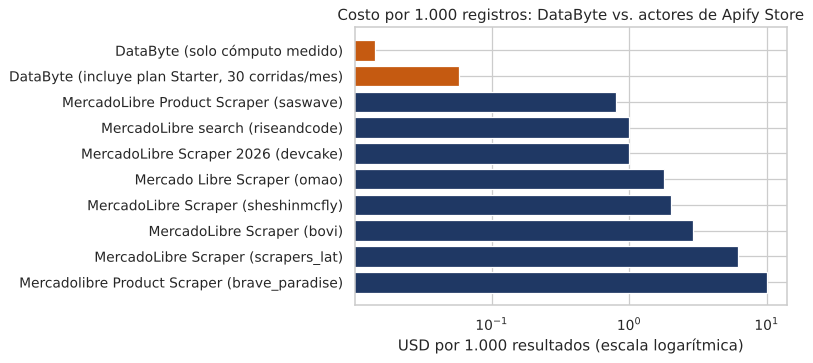

In [4]:
ACTORES = pd.DataFrame([
    ("MercadoLibre Product Scraper (saswave)", 0.80, "https://apify.com/saswave/mercadolibre-product-scraper"),
    ("MercadoLibre search (riseandcode)", 1.00, "https://apify.com/riseandcode/apify-mercadolivre-search"),
    ("MercadoLibre Scraper 2026 (devcake)", 1.00, "https://apify.com/devcake/mercadolibre-scraper"),
    ("Mercado Libre Scraper (omao)", 1.80, "https://apify.com/omao/mercado-libre-scraper"),
    ("MercadoLibre Scraper (sheshinmcfly)", 2.00, "https://apify.com/sheshinmcfly/mercadolibre-scraper"),
    ("MercadoLibre Scraper (bovi)", 2.91, "https://apify.com/bovi/mercadolibre-scraper"),
    ("MercadoLibre Scraper (scrapers_lat)", 6.15, "https://apify.com/scrapers_lat/mercadolibre-scraper"),
    ("Mercadolibre Product Scraper (brave_paradise)", 10.00, "https://apify.com/brave_paradise/mercadolibre-product-scraper/api/cli"),
], columns=["actor", "usd_por_1000_resultados", "url"])

costo_1000_computo = MEDIDO["costo_corrida_usd"] / MEDIDO["registros"] * 1000
registros_mes_diario = MEDIDO["registros"] * CORRIDAS_MES_DIARIO
costo_1000_plan = max(APIFY_STARTER_MES, CORRIDAS_MES_DIARIO * MEDIDO["costo_corrida_usd"]) / registros_mes_diario * 1000
nuestro = pd.DataFrame([
    ("DataByte (solo cómputo medido)", costo_1000_computo, "Captura de Apify"),
    ("DataByte (incluye plan Starter, 30 corridas/mes)", costo_1000_plan, "Plan Starter + 30 corridas"),
], columns=["actor", "usd_por_1000_resultados", "url"])
bench = pd.concat([nuestro, ACTORES]).reset_index(drop=True)
bench["veces_mas_barato_que_mediana_mercado"] = (ACTORES.usd_por_1000_resultados.median() / bench.usd_por_1000_resultados).round(1)
print(f"Mediana de los actores de mercado: USD {ACTORES.usd_por_1000_resultados.median():.2f} por 1.000 resultados (rango {ACTORES.usd_por_1000_resultados.min():.2f}–{ACTORES.usd_por_1000_resultados.max():.2f}).")
print(f"DataByte: USD {costo_1000_computo:.3f} (solo cómputo) / USD {costo_1000_plan:.3f} (con plan mensual) por 1.000 registros.")
fig, ax = plt.subplots(figsize=(9, 4.2))
col = ["#C55A11" if a.startswith("DataByte") else "#1F3864" for a in bench.actor]
ax.barh(bench.actor[::-1], bench.usd_por_1000_resultados[::-1], color=col[::-1]); ax.set_xscale("log")
ax.set_xlabel("USD por 1.000 resultados (escala logarítmica)"); ax.set_title("Costo por 1.000 registros: DataByte vs. actores de Apify Store")
plt.tight_layout()
bench[["actor", "usd_por_1000_resultados", "veces_mas_barato_que_mediana_mercado", "url"]].round(3)

**Conclusión honesta:** nuestro costo por registro es mucho menor al de los actores públicos, pero (1) no incluye las horas que costó *construir* nuestro actor (están en el presupuesto de desarrollo), y (2) un actor público
también cubre la parte de *mantenimiento* (si la web cambia). Por eso en la operación mensual reservamos horas de mantenimiento.

### 3.B Tiempo: extracción automática vs. relevamiento manual
Diana hoy relee precios a mano 12 h por semana. ¿Cuánto tardaría una persona en juntar lo que extrajimos en 1 hora? Depende de cuánto demora cada precio: **no lo medimos todavía** (por eso es un supuesto con sensibilidad; pedirle a Diana que cronometre 10 precios).

In [5]:
seg = np.array([15, 30, 60, 120])
t = pd.DataFrame({"segundos por precio (SUPUESTO)": seg})
t["horas manuales para 22.438 precios"] = (MEDIDO["registros"] * seg / 3600).round(0)
t["semanas de trabajo de Diana (12 h/sem)"] = (t["horas manuales para 22.438 precios"] / FICHA["horas_semana_manual"]).round(1)
t["horas ahorradas vs. 1 h de Apify"] = t["horas manuales para 22.438 precios"] - 1
t["factor de aceleración"] = (t["horas manuales para 22.438 precios"] / 1).round(0)
print(f"Con {SEG_POR_PRECIO_MANUAL} s por precio, juntar lo que Apify trae en 1 hora llevaría {MEDIDO['registros']*SEG_POR_PRECIO_MANUAL/3600:,.0f} horas.")
t

Con 30 s por precio, juntar lo que Apify trae en 1 hora llevaría 187 horas.

,segundos por precio (SUPUESTO),horas manuales para 22.438 precios,semanas de trabajo de Diana (12 h/sem),horas ahorradas vs. 1 h de Apify,factor de aceleración
0,15,93.0,7.8,92.0,93.0
1,30,187.0,15.6,186.0,187.0
2,60,374.0,31.2,373.0,374.0
3,120,748.0,62.3,747.0,748.0


### 3.C Costo de construir: tarifas de Upwork
Horas del equipo valoradas con el extremo inferior de los rangos publicados (equipo junior): Data Scientist **USD 35–250/h**, analistas de datos **USD 20–50/h**, project managers **USD 19–45/h**
(ver fuentes). Esto sale de la hoja `Presupuesto` del Excel del Capstone.

In [6]:
filas = []
for etapa, h in HORAS.items():
    for rol, horas in h.items():
        filas.append((etapa, f"Horas {rol}", horas, TARIFA_HORA[rol], horas * TARIFA_HORA[rol]))
herr_setup = [("Etapa 1", "n8n Cloud Starter (1 mes)", 1, N8N_STARTER_MES), ("Etapa 1", "Apify: corridas de prueba (5 x USD 0,315)", 5, MEDIDO["costo_corrida_usd"]),
              ("Etapa 2", "n8n Cloud Starter (1 mes)", 1, N8N_STARTER_MES)]
for etapa, nombre, q, u in herr_setup:
    filas.append((etapa, nombre, q, u, q * u))
setup = pd.DataFrame(filas, columns=["etapa", "concepto", "cantidad", "costo_unitario_usd", "subtotal_usd"])
costo_etapa = setup.groupby("etapa").subtotal_usd.sum()
precio_etapa = costo_etapa * (1 + MARCA_CONSULTORA)
costo_setup, PRECIO_SETUP = costo_etapa.sum(), precio_etapa.sum()
print(f"Costo de desarrollo: USD {costo_setup:,.2f} | con margen {MARCA_CONSULTORA:.0%} -> PRECIO al cliente: USD {PRECIO_SETUP:,.2f} (tope de Diana: USD {FICHA['presupuesto_setup']:,}).")
print("Entra en el presupuesto:", "SÍ" if PRECIO_SETUP <= FICHA["presupuesto_setup"] else "NO", f"(sobran USD {FICHA['presupuesto_setup']-PRECIO_SETUP:,.2f})")
setup.round(2)

Costo de desarrollo: USD 1,839.58 | con margen 30% -> PRECIO al cliente: USD 2,391.45 (tope de Diana: USD 2,500).
Entra en el presupuesto: SÍ (sobran USD 108.55)

,etapa,concepto,cantidad,costo_unitario_usd,subtotal_usd
0,Etapa 1,Horas DS,12,35.00,420.00
1,Etapa 1,Horas SE,14,25.00,350.00
2,Etapa 1,Horas BIZ,8,20.00,160.00
3,Etapa 2,Horas DS,14,35.00,490.00
4,Etapa 2,Horas SE,10,25.00,250.00
5,Etapa 2,Horas BIZ,6,20.00,120.00
6,Etapa 1,n8n Cloud Starter (1 mes),1,24.00,24.00
7,Etapa 1,"Apify: corridas de prueba (5 x USD 0,315)",5,0.32,1.58
8,Etapa 2,n8n Cloud Starter (1 mes),1,24.00,24.00


**Por qué entra en el tope de Diana:** el desarrollo ya existe (bot, ETL y actor); a ella le cobramos las horas de *adaptación y entrega*, no las de invención. Si pide más funciones por el mismo presupuesto (p. ej. predicción de demanda con ML), hay que **negociar alcance, plazo o precio**.

## 4. Costos de operación mensual y qué herramientas se contabilizan
**Pregunta del equipo:** ¿cuentan Apify, n8n y la app que hizo Ayelen en FlutterFlow? **Sí, todo lo que Diana tendría que pagar o mantener para que el sistema funcione se contabiliza**:

In [7]:
contab = pd.DataFrame([
    ("Apify (extracción de precios)", "Sí", f"USD 0,315 por corrida (medido); plan Starter USD {APIFY_STARTER_MES}/mes para monitoreo diario. Plan Free (USD 5 de crédito) alcanza para ~4 corridas/mes."),
    ("n8n (automatización)", "Sí", f"USD {N8N_STARTER_MES}/mes (Starter, 2.500 ejecuciones; el monitoreo diario usa ~30–60)."),
    ("Dashboard en AppSheet / Looker Studio", "Sí", f"AppSheet Starter USD {APPSHEET_USUARIO}/usuario/mes x 3 usuarios. Looker Studio no tiene costo de licencia en su uso estándar (verificar)."),
    ("Google Sheets (base de datos)", "No (USD 0)", "Plan gratuito de Google; el riesgo es el límite de cuota (ver riesgos)."),
    ("Bot de Telegram", "Horas sí / hosting a cotizar", "Hoy corre en la PC del equipo. Si lo aloja el cliente, hay que sumar un servidor (no medido)."),
    ("App móvil en FlutterFlow (Ayelen)", "Sí, como OPCIONAL", f"Horas de desarrollo (a tarifa SE) + FlutterFlow Basic USD {FLUTTERFLOW_BASIC}/mes (primer plan que permite exportar código y publicar). La versión Free sirve para prototipo."),
    ("Horas de mantenimiento", "Sí", f"{MANTENIMIENTO_H_MES} h/mes a USD {TARIFA_HORA['BIZ']}/h por si cambia el sitio de origen."),
], columns=["componente", "¿se contabiliza?", "cómo"])
contab

,componente,¿se contabiliza?,cómo
0,Apify (extracción de precios),Sí,"USD 0,315 por corrida (medido); plan Starter USD 39/mes para monitoreo diario. Plan Free (USD 5 de crédito) alcanza para ~4 corridas/mes."
1,n8n (automatización),Sí,"USD 24/mes (Starter, 2.500 ejecuciones; el monitoreo diario usa ~30–60)."
2,Dashboard en AppSheet / Looker Studio,Sí,AppSheet Starter USD 5/usuario/mes x 3 usuarios. Looker Studio no tiene costo de licencia en su uso estándar (verificar).
3,Google Sheets (base de datos),No (USD 0),Plan gratuito de Google; el riesgo es el límite de cuota (ver riesgos).
4,Bot de Telegram,Horas sí / hosting a cotizar,"Hoy corre en la PC del equipo. Si lo aloja el cliente, hay que sumar un servidor (no medido)."
5,App móvil en FlutterFlow (Ayelen),"Sí, como OPCIONAL",Horas de desarrollo (a tarifa SE) + FlutterFlow Basic USD 39/mes (primer plan que permite exportar código y publicar). La versión Free sirve para prototipo.
6,Horas de mantenimiento,Sí,2 h/mes a USD 20/h por si cambia el sitio de origen.


In [8]:
mant = MANTENIMIENTO_H_MES * TARIFA_HORA["BIZ"]
mensual = pd.DataFrame([
    ("n8n Cloud Starter", N8N_STARTER_MES, N8N_STARTER_MES),
    ("Apify", APIFY_STARTER_MES, CORRIDAS_MES_SEMANAL * MEDIDO["costo_corrida_usd"]),
    (f"AppSheet Starter x {FICHA['personas_equipo']} usuarios", APPSHEET_USUARIO * FICHA["personas_equipo"], APPSHEET_USUARIO * FICHA["personas_equipo"]),
    (f"Mantenimiento ({MANTENIMIENTO_H_MES} h)", mant, mant),
], columns=["concepto", "A_monitoreo_diario_usd", "B_piloto_semanal_usd"])
total = mensual[["A_monitoreo_diario_usd", "B_piloto_semanal_usd"]].sum()
mensual.loc[len(mensual)] = ["TOTAL operación por mes", total.iloc[0], total.iloc[1]]
OPEX = {"A": float(total.iloc[0]), "B": float(total.iloc[1])}
print(f"Operación mensual: A (diario) USD {OPEX['A']:.2f} | B (piloto semanal) USD {OPEX['B']:.2f} | tope de Diana: USD {FICHA['presupuesto_mes']}")
mensual.round(2)

Operación mensual: A (diario) USD 118.00 | B (piloto semanal) USD 80.26 | tope de Diana: USD 150

,concepto,A_monitoreo_diario_usd,B_piloto_semanal_usd
0,n8n Cloud Starter,24.0,24.00
1,Apify,39.0,1.26
2,AppSheet Starter x 3 usuarios,15.0,15.00
3,Mantenimiento (2 h),40.0,40.00
4,TOTAL operación por mes,118.0,80.26


## 5. ROI con los datos de Diana
Fórmula de la guía del Capstone: **ROI = (beneficio − costo) / costo**, aquí a 12 meses.
* **Beneficio medido con la ficha:** horas de relevamiento que dejan de hacerse a mano × costo de la hora de Diana (USD 8).
* **Costo:** precio de desarrollo + operación de 12 meses.
* **Plazo de recuperación** = precio de desarrollo ÷ (ahorro mensual − operación mensual).

In [9]:
def roi(opex_mes, setup_usd=None, horas_residuales=HORAS_RESIDUALES_SEMANA, extra_ingreso_mes=0.0):
    setup_usd = PRECIO_SETUP if setup_usd is None else setup_usd
    ahorro = (FICHA["horas_semana_manual"] - horas_residuales) * SEMANAS_MES * FICHA["costo_hora_usd"]
    neto_mes = ahorro + extra_ingreso_mes - opex_mes
    costo_12m = setup_usd + opex_mes * 12
    beneficio_12m = (ahorro + extra_ingreso_mes) * 12
    return dict(ahorro_mes=ahorro, operacion_mes=opex_mes, neto_mes=neto_mes, inversion_inicial=setup_usd,
                costo_12m=costo_12m, beneficio_12m=beneficio_12m, ganancia_neta_12m=beneficio_12m - costo_12m,
                ROI_12m=(beneficio_12m - costo_12m) / costo_12m, payback_meses=(setup_usd / neto_mes) if neto_mes > 0 else np.inf)

base = pd.DataFrame({"A) Monitoreo diario": roi(OPEX["A"]), "B) Piloto semanal": roi(OPEX["B"])}).T
fmt = base.copy()
fmt["ROI_12m"] = (fmt.ROI_12m * 100).round(1).astype(str) + " %"
fmt["payback_meses"] = fmt.payback_meses.round(1)
print("Ahorro MEDIDO con la ficha de Diana, SIN contar ventas adicionales:")
fmt.round(2)

Ahorro MEDIDO con la ficha de Diana, SIN contar ventas adicionales:

,ahorro_mes,operacion_mes,neto_mes,inversion_inicial,costo_12m,beneficio_12m,ganancia_neta_12m,ROI_12m,payback_meses
A) Monitoreo diario,346.67,118.00,228.67,2391.45,3807.45,4160.0,352.55,9.3 %,10.5
B) Piloto semanal,346.67,80.26,266.41,2391.45,3354.57,4160.0,805.43,24.0 %,9.0


**Cómo leerlo:** con solo el ahorro de horas (sin contar ninguna venta extra), la inversión se recupera en alrededor de **9–10 meses** y el primer año queda levemente positivo. Es un ROI **conservador y honesto**; el valor grande
no está en las horas sino en **decidir antes** (la queja de Diana: «llego tarde y pierdo ventas»), que mostramos como escenario aparte.

,horas_que_siguen_manuales_por_semana,pct_automatizado,plan,ROI_12m_pct,payback_meses
0,1,92%,A diario,20.2,9.1
1,1,92%,B semanal,36.4,7.9
2,2,83%,A diario,9.3,10.5
3,2,83%,B semanal,24.0,9.0
4,3,75%,A diario,-1.7,12.3
5,3,75%,B semanal,11.6,10.3
6,4,67%,A diario,-12.6,15.0
7,4,67%,B semanal,-0.8,12.1
8,6,50%,A diario,-34.4,26.6
9,6,50%,B semanal,-25.6,18.7


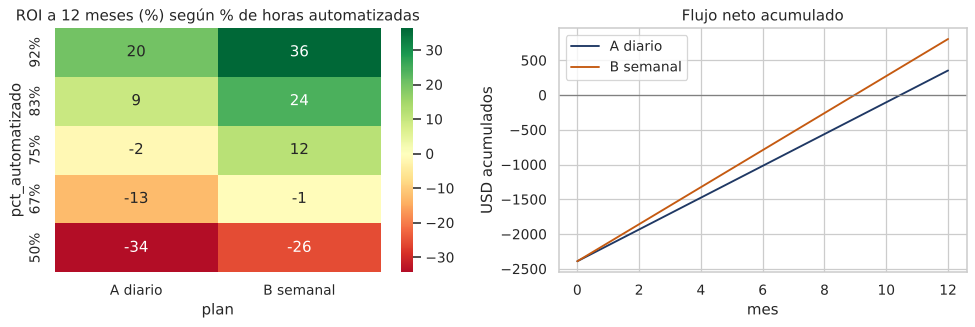

In [10]:
# Sensibilidad: ¿y si se automatizan menos (o más) horas que las 10 supuestas?
filas = []
for resid in [1, 2, 3, 4, 6]:
    for nombre, opex in [("A diario", OPEX["A"]), ("B semanal", OPEX["B"])]:
        r = roi(opex, horas_residuales=resid)
        filas.append(dict(horas_que_siguen_manuales_por_semana=resid, pct_automatizado=f"{(12-resid)/12:.0%}", plan=nombre,
                          ROI_12m_pct=round(r["ROI_12m"] * 100, 1), payback_meses=round(r["payback_meses"], 1) if np.isfinite(r["payback_meses"]) else None))
sens = pd.DataFrame(filas)
piv = sens.pivot(index="pct_automatizado", columns="plan", values="ROI_12m_pct").sort_index(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(piv, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax[0]); ax[0].set_title("ROI a 12 meses (%) según % de horas automatizadas")
meses = np.arange(0, 13)
for nombre, opex, color in [("A diario", OPEX["A"], "#1F3864"), ("B semanal", OPEX["B"], "#C55A11")]:
    r = roi(opex); ax[1].plot(meses, -PRECIO_SETUP + r["neto_mes"] * meses, label=nombre, color=color)
ax[1].axhline(0, color="gray", lw=1); ax[1].set_xlabel("mes"); ax[1].set_ylabel("USD acumulados"); ax[1].set_title("Flujo neto acumulado"); ax[1].legend()
plt.tight_layout()
sens

### 5.1 Lo que NO está en el ROI base (y por qué)
* **Ventas adicionales por decidir antes:** el dato que falta es el *margen* de Diana. Mostramos el escenario por separado, no lo sumamos al ROI base.
* **Errores de carga (1 de cada 10 publicaciones):** no tenemos cuánto cuesta cada error ni cuántas publicaciones hace por mes. Medido: nuestro pipeline entrega **0 nulos, 0 duplicados y 0 EAN inválidos**; no podemos afirmar «0 % de error» porque no auditamos contra la fuente.
* **NPS (22):** se puede mejorar con precios y promociones a tiempo, pero no se cuantifica en USD sin datos de recompra.

In [11]:
# Escenario upside (NO incluido en el ROI base): cuánto aportan las ventas adicionales si la decisión llega a tiempo
filas = []
for uplift in [0, 0.01, 0.02, 0.03]:
    venta_extra = FICHA["ventas_meta_mes_usd"] * uplift
    for margen in [0.15, 0.25, 0.35]:     # SUPUESTO: margen bruto de Diana (dato a pedirle)
        r = roi(OPEX["A"], extra_ingreso_mes=venta_extra * margen)
        filas.append(dict(ventas_extra_pct=f"{uplift:.0%}", ventas_extra_usd_mes=venta_extra, margen_bruto=f"{margen:.0%}",
                          contribucion_extra_usd_mes=round(venta_extra * margen, 1), ROI_12m_pct=round(r["ROI_12m"] * 100, 1),
                          payback_meses=round(r["payback_meses"], 1)))
upside = pd.DataFrame(filas)
upside[upside.ventas_extra_pct != "0%"].pivot_table(index="ventas_extra_pct", columns="margen_bruto", values="payback_meses")

margen_bruto,15%,25%,35%
ventas_extra_pct,,,
1%,9.5,9.0,8.5
2%,8.7,7.9,7.2
3%,8.1,7.0,6.2


**Para el pitch:** *«Solo con el ahorro de horas recuperamos la inversión en ~10 meses. Si la solución logra que usted venda 1 % más (USD 150/mes sobre su meta de USD 15.000), el plazo baja y el ROI sube; para
confirmarlo le proponemos un piloto de 4 semanas midiendo horas reales y ventas.»*

## 6. Guardar resultados para el Excel, AppSheet y el dashboard

In [12]:
bench_out = bench[["actor", "usd_por_1000_resultados", "url"]].round(4)
bench_out.to_csv(OUT / "benchmarks_apify.csv", index=False)
setup.to_csv(OUT / "costos_desarrollo.csv", index=False)
mensual.to_csv(OUT / "costos_operacion_mensual.csv", index=False)
roi_tab = base.reset_index().rename(columns={"index": "escenario"}); roi_tab.to_csv(OUT / "roi_escenarios.csv", index=False)
sens.to_csv(OUT / "roi_sensibilidad.csv", index=False); upside.to_csv(OUT / "roi_upside_ventas.csv", index=False)
contab.to_csv(OUT / "que_se_contabiliza.csv", index=False)
params = dict(ficha=FICHA, medido=MEDIDO, tarifa_hora=TARIFA_HORA, horas=HORAS, n8n_mes=N8N_STARTER_MES, apify_mes=APIFY_STARTER_MES,
              appsheet_usuario=APPSHEET_USUARIO, flutterflow_basic=FLUTTERFLOW_BASIC, margen=MARCA_CONSULTORA,
              horas_residuales=HORAS_RESIDUALES_SEMANA, mantenimiento_h=MANTENIMIENTO_H_MES, seg_por_precio=SEG_POR_PRECIO_MANUAL,
              costo_desarrollo=round(float(costo_setup), 2), precio_desarrollo=round(float(PRECIO_SETUP), 2),
              costo_por_etapa={k: round(float(v), 2) for k, v in costo_etapa.items()}, precio_por_etapa={k: round(float(v), 2) for k, v in precio_etapa.items()},
              opex_mes=OPEX, roi={k: {a: float(b) for a, b in v.items()} for k, v in base.T.to_dict().items()},
              costo_1000_computo=float(costo_1000_computo), costo_1000_plan=float(costo_1000_plan),
              mediana_mercado_1000=float(ACTORES.usd_por_1000_resultados.median()), ahorro_mes=float(ahorro_mes), costo_manual_mes=float(costo_manual_mes))
(OUT / "parametros_negocio.json").write_text(json.dumps(params, ensure_ascii=False, indent=1))
print("Guardado en", OUT.resolve())

Guardado en /mnt/user-data/outputs/rescatealimento-databyte/data/processed

## 7. Fuentes (consultadas el 23/11/2026)
| Dato | Valor usado | URL |
|---|---|---|
| Ficha del cliente (Diana) | 12 h/sem, USD 8/h, 1 de 10 errores, meta USD 15.000, tope USD 2.500 + 150/mes | Excel del Capstone, hoja *Resumen* |
| Corrida de Apify | 22.438 registros, 1 h, USD 0,315 | Captura propia del 15/11/2026 |
| n8n Cloud | Starter 24 €/mes mensual (20 € anual), 2.500 ejecuciones | https://n8n.io/pricing |
| Apify planes | Free USD 5 de crédito; planes Starter pagos (los sitios de comparación difieren: USD 29–39, usamos 39 por prudencia) | https://apify.com/pricing · https://docs.apify.com/account/subscriptions |
| Actores de Mercado Libre (USD por 1.000 resultados) | 0,80 a 10,00 | https://apify.com/saswave/mercadolibre-product-scraper · https://apify.com/riseandcode/apify-mercadolivre-search · https://apify.com/devcake/mercadolibre-scraper · https://apify.com/omao/mercado-libre-scraper · https://apify.com/sheshinmcfly/mercadolibre-scraper · https://apify.com/bovi/mercadolibre-scraper · https://apify.com/scrapers_lat/mercadolibre-scraper · https://apify.com/brave_paradise/mercadolibre-product-scraper/api/cli |
| Tarifas Upwork | Data Scientist USD 35–250/h | https://www.upwork.com/hire/data-scientists/cost/ |
| Tarifas freelance | Analistas de datos USD 20–50/h; project managers USD 19–45/h | https://www.upwork.com/en-gb/resources/how-much-do-freelancers-make |
| AppSheet | Starter USD 5 y Core USD 10 por usuario/mes; gratis para prototipo | https://about.appsheet.com/pricing · https://www.capterra.com/p/149367/AppSheet/pricing/ |
| FlutterFlow | Free USD 0 (sin exportar código); Basic USD 39/mes (USD 29 anual) con exportación de código; GitHub desde planes superiores | https://flutterflow.io/pricing · https://docs.flutterflow.io/accounts-billing/plan-pricing |

> Los precios de herramientas cambian: **volver a verificarlos antes de presentar** y anotar la fecha. Los de n8n están en euros; se tomaron los valores en USD publicados por reseñas de 2026 como aproximación.